# Qiskit Fall Fest 2026 – Challenge 4: Quantum Correlation Switch

**Goal:** Build a 2-qubit circuit that produces *correlated* outcomes (`00`, `11`) and then switch it, with a small change, to produce *opposite* outcomes (`01`, `10`). Each experiment uses 100 shots.

**Gates used (all from the workshop):** `H` (Hadamard), `CX` (CNOT), `X` (NOT).

| Part | Circuit | Gates before measurement | Final state |
|---|---|---|---|
| A | H(q0) → CX(q0→q1) | 2 | (\|00⟩ + \|11⟩)/√2 |
| B | H(q0) → CX(q0→q1) → X(q1) | 3 | (\|01⟩ + \|10⟩)/√2 |

> Qiskit prints bitstrings as `q1 q0`, with qubit 0 on the right.

In [1]:
# !pip install qiskit qiskit-aer matplotlib pylatexenc   # uncomment if needed
from qiskit import QuantumCircuit
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

SHOTS = 100
sim = AerSimulator()

def run(qc, shots=SHOTS):
    return sim.run(qc, shots=shots).result().get_counts()

def share(counts, outcomes):
    """Fraction of shots that landed in the given outcomes."""
    return sum(counts.get(o, 0) for o in outcomes) / sum(counts.values())

def correlation_circuit(opposite=False):
    """The 'switch': opposite=False -> correlated, opposite=True -> opposite outcomes."""
    qc = QuantumCircuit(2, 2)
    qc.h(0)
    qc.cx(0, 1)
    if opposite:
        qc.x(1)          # the switch: flips qubit 1
    qc.measure([0, 1], [0, 1])
    return qc

## Predictions (before running)

**Part A (H, CX):**
- `00` and `11` should dominate, about 50 % each (~50 shots each).
- `01` and `10` should not appear (≈ 0 %). So **not all four outcomes appear**.

**Part B (H, CX, X on q1):**
- `01` and `10` should dominate, about 50 % each.
- `00` and `11` should not appear.

**Why some outcomes are far more frequent than others:** the qubits are entangled. After the CNOT, the amplitude on two of the four basis states is exactly zero, so only two outcomes are possible, each with probability 1/2. The choice between 00/11 and 01/10 is random, but the *relationship* between the two bits is fixed.

## Part A – Correlated outcomes

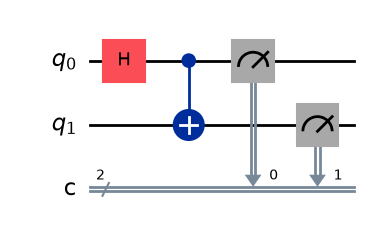

Part A counts: {'00': 54, '11': 46}
Share in 00/11: 100%


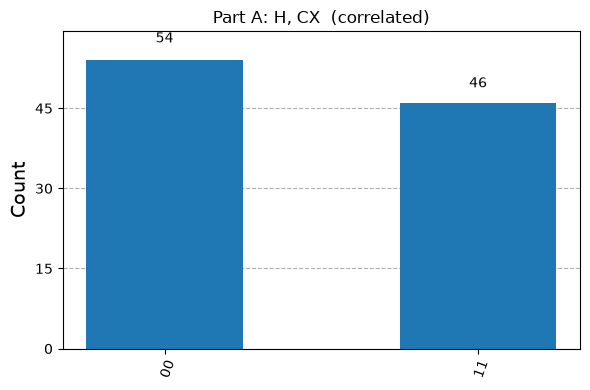

In [2]:
qc_A = correlation_circuit(opposite=False)
display(qc_A.draw(output='mpl'))   # use print(qc_A.draw()) if mpl is unavailable

counts_A = run(qc_A)
print("Part A counts:", dict(sorted(counts_A.items())))
print(f"Share in 00/11: {share(counts_A, ['00','11']):.0%}")
display(plot_histogram(counts_A, title="Part A: H, CX  (correlated)", figsize=(6,4)))

## Part B – Opposite outcomes

The only change is one extra `X` gate on qubit 1, placed after the CNOT.

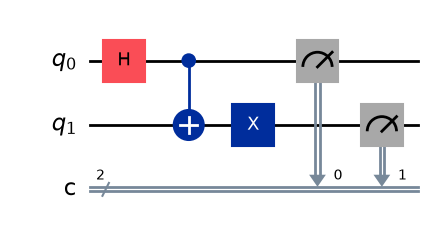

Part B counts: {'01': 50, '10': 50}
Share in 01/10: 100%


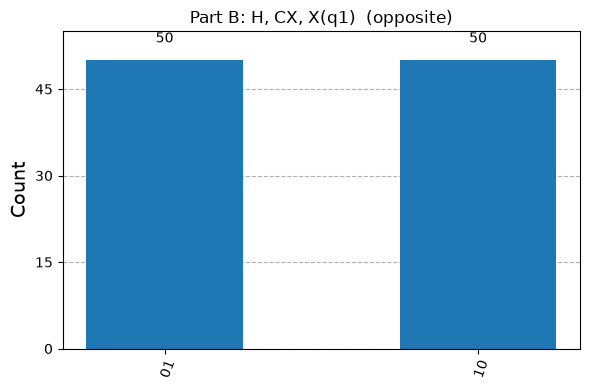

In [3]:
qc_B = correlation_circuit(opposite=True)
display(qc_B.draw(output='mpl'))

counts_B = run(qc_B)
print("Part B counts:", dict(sorted(counts_B.items())))
print(f"Share in 01/10: {share(counts_B, ['01','10']):.0%}")
display(plot_histogram(counts_B, title="Part B: H, CX, X(q1)  (opposite)", figsize=(6,4)))

## Part C – Comparison

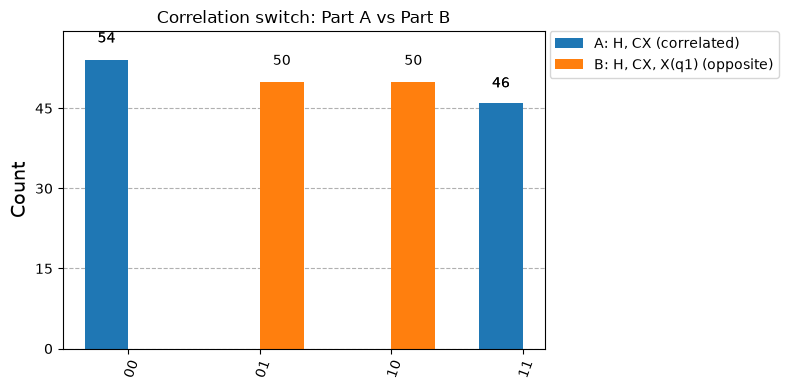

In [4]:
plot_histogram([counts_A, counts_B],
               legend=['A: H, CX (correlated)', 'B: H, CX, X(q1) (opposite)'],
               title="Correlation switch: Part A vs Part B", figsize=(8,4))

In [5]:
import pandas as pd   # optional: summary table (pip install pandas if missing)
rows = []
for name, c in [("A (H, CX)", counts_A), ("B (H, CX, X)", counts_B)]:
    rows.append({"Circuit": name,
                 **{o: c.get(o, 0) for o in ['00','01','10','11']},
                 "Same bits (00+11)": c.get('00',0) + c.get('11',0),
                 "Opposite bits (01+10)": c.get('01',0) + c.get('10',0)})
pd.DataFrame(rows).set_index("Circuit")

,00,01,10,11,Same bits (00+11),Opposite bits (01+10)
Circuit,,,,,,
"A (H, CX)",54,0,0,46,100,0
"B (H, CX, X)",0,50,50,0,0,100


### Answers

- **Dominant outcomes in Part A:** `00` and `11` (about 50 % each); the two bits always match.
- **Dominant outcomes in Part B:** `01` and `10` (about 50 % each); the two bits always differ.
- **What changed between the circuits:** one extra `X` gate on qubit 1, applied after the CNOT and before measurement.
- **Why the relationship changed:** Part A creates the Bell state (|00⟩ + |11⟩)/√2. The Hadamard puts qubit 0 in superposition and the CNOT copies its value onto qubit 1 in an entangled way, so the two results are always equal. The `X` gate swaps the |0⟩ and |1⟩ components of qubit 1, so (|00⟩ + |11⟩)/√2 becomes (|01⟩ + |10⟩)/√2. The qubits remain entangled, but whenever qubit 0 gives 0, qubit 1 now gives 1, and vice versa.

The counts will not be exactly 50/50 because 100 shots is a small sample (typically within about ±5 of 50). On a real quantum device, a few shots could also land in the "forbidden" outcomes due to gate and readout noise.

## Short explanation: how the circuit produces the different correlations

1. **H on qubit 0** creates an equal superposition of 0 and 1, which gives the randomness.
2. **CX (control q0, target q1)** entangles the qubits so qubit 1 follows qubit 0, producing perfectly *correlated* results (`00` / `11`).
3. **X on qubit 1 (optional switch)** flips qubit 1 after entanglement, so it now does the opposite of qubit 0, producing *anti-correlated* results (`01` / `10`).

Turning the `X` gate on or off therefore switches the relationship between the two measured bits, while each individual qubit still looks like a fair coin (50 % 0 / 50 % 1).